**PUNTO 4**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../datos/train.csv")
df2 = df.copy()
df2.shape

(891, 12)

In [5]:
df2["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [6]:
df2.duplicated().sum()

np.int64(0)

In [7]:
df2["Embarked"].value_counts(dropna=False)

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

In [8]:
(df2["Name"] != df2["Name"].str.strip()).sum()

np.int64(2)

In [9]:
df2["Name"] = df2["Name"].str.strip()
(df2["Name"] != df2["Name"].str.strip()).sum()

np.int64(0)

In [10]:
df2["Name"].duplicated().sum()

np.int64(0)

In [11]:
df2["Ticket"].duplicated().sum()

np.int64(210)

**PUNTO 6**

In [12]:
mujeres_1 = df[(df["Sex"] == "female") & (df["Pclass"] == 1)]
print(f"Mujeres en 1ª clase: {len(mujeres_1)} | sobrevivieron: {mujeres_1['Survived'].mean():.1%}")

Mujeres en 1ª clase: 94 | sobrevivieron: 96.8%


In [13]:
ninos = df[df["Age"] < 12]
print(f"Niños menores de 12: {len(ninos)} | sobrevivieron: {ninos['Survived'].mean():.1%}")


Niños menores de 12: 68 | sobrevivieron: 57.4%


In [14]:
hombres_3 = df[(df["Sex"] == "male") & (df["Pclass"] == 3)]
print(f"Hombres en 3ª clase: {len(hombres_3)} | sobrevivieron: {hombres_3['Survived'].mean():.1%}")

Hombres en 3ª clase: 347 | sobrevivieron: 13.5%


In [15]:
solos = df[(df["SibSp"] == 0) & (df["Parch"] == 0)]
acompanados = df[(df["SibSp"] > 0) | (df["Parch"] > 0)]
print(f"Solos: {len(solos)} | sobrevivieron: {solos['Survived'].mean():.1%}")
print(f"Con familia: {len(acompanados)} | sobrevivieron: {acompanados['Survived'].mean():.1%}")

Solos: 537 | sobrevivieron: 30.4%
Con familia: 354 | sobrevivieron: 50.6%


In [16]:
df.nlargest(5, "Fare")[["Name", "Pclass", "Sex", "Fare", "Survived"]]

,Name,Pclass,Sex,Fare,Survived
258,"Ward, Miss. Anna",1,female,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,male,512.3292,1
737,"Lesurer, Mr. Gustave J",1,male,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,male,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,female,263.0000,1


**Punto 8 Visualizaciones**

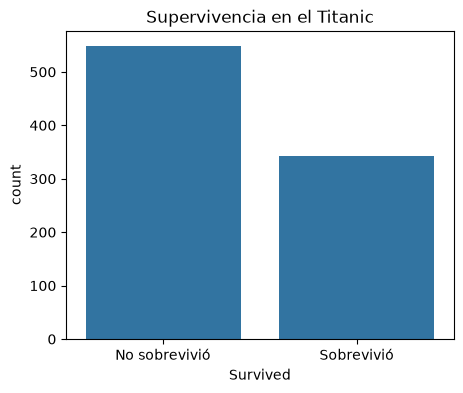

In [17]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Survived")
plt.xticks([0, 1], ["No sobrevivió", "Sobrevivió"])
plt.title("Supervivencia en el Titanic")
plt.show()

In [1]:
# %% [markdown]
# **Conclusión 1:** Sobrevivieron 342 de 891 pasajeros (38,4 %), mientras que 549 murieron. Hay más fallecidos que sobrevivientes, por lo que el conjunto no está equilibrado.

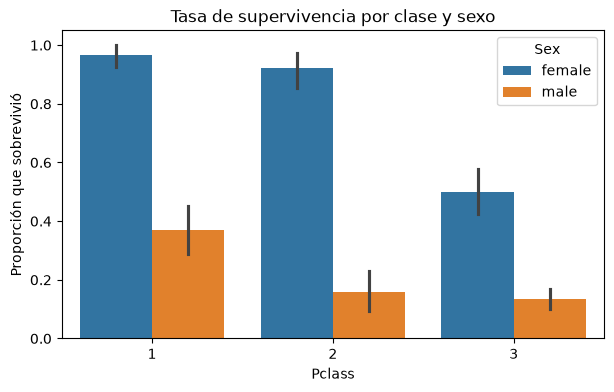

In [18]:
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex")
plt.title("Tasa de supervivencia por clase y sexo")
plt.ylabel("Proporción que sobrevivió")
plt.show()

In [2]:
# %% [markdown]
# **Conclusión 2:** En las tres clases las mujeres sobrevivieron mucho más que los hombres (en primera, 96,8 % frente a 36,9 %). La clase también pesa: las mujeres de tercera clase bajan al 50 %.

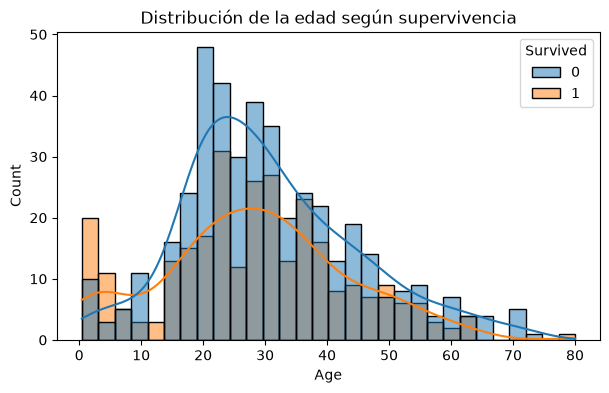

In [19]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True)
plt.title("Distribución de la edad según supervivencia")
plt.show()

In [4]:
# %% [markdown]
# **Conclusión 3:** La mediana de edad es 28 años tanto en sobrevivientes como en no sobrevivientes, así que la edad por sí sola casi no marca diferencia. Solo los niños pequeños muestran más supervivencia. El pico alrededor de 28 se debe en parte a la imputación con la mediana.

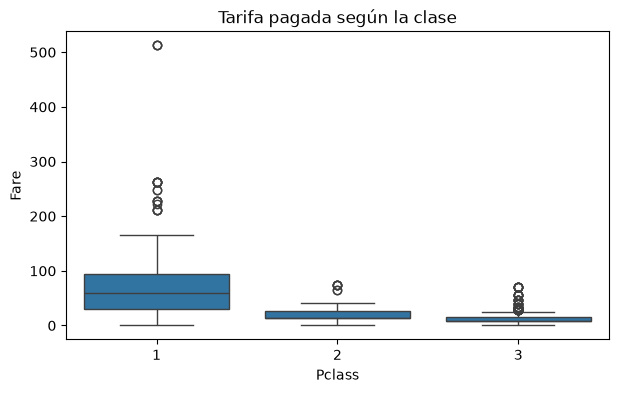

In [20]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Pclass", y="Fare")
plt.title("Tarifa pagada según la clase")
plt.show()

In [5]:
# %% [markdown]
# **Conclusión 4:** La tarifa aumenta con la clase: la mediana es 60,3 en primera, 14,2 en segunda y 8,0 en tercera. En primera clase hay valores muy altos y aislados, de hasta 512.

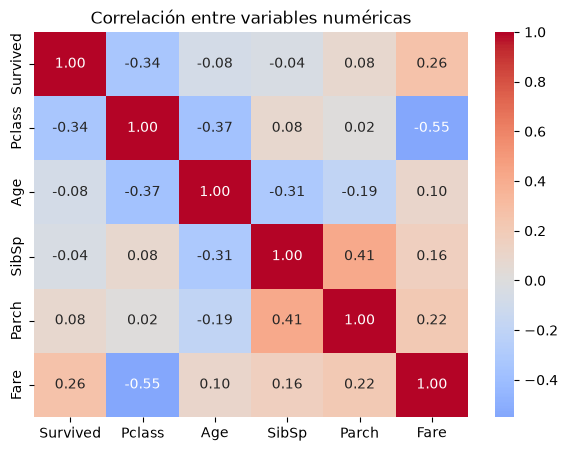

In [21]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(columns="PassengerId").corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas")
plt.show()

In [6]:
# %% [markdown]
# **Conclusión 5:** Las variables más relacionadas con `Survived` son `Pclass` (−0,34) y `Fare` (0,26). Son relaciones moderadas o débiles, así que ninguna variable explica por sí sola la supervivencia.